# Grenoble from scratch: LTS and Degree of Separation (DoS), 2017–2022 + 2026

For a **new computer / no cache**. Everything is downloaded from Overpass into a new run folder, then:

1. **LTS** (same method as `notebooks/01_build_lts_networks.ipynb`): bike LTS 1–4 for 2017–2022 and 2026, plus car roads as LTS 5 in 2026, simplified graphs and metrics.
2. **DoS** (same method as `Grenoble_DoS_2017_2022_2026.ipynb`): the Geovélo `sql/*.sql` rules → `tagsmapping.csv` → `tags_mapping_final.csv` → DoS 6 (a_High) … DoS 1 (f_Null_or_Others), plus car roads (DoS 0) in 2026.

Both are built from **the same downloads**. The LTS step downloads each OSM snapshot, and the DoS step reads the same responses from the run's cache (only the small "footways where bikes are allowed" query is extra).

**Files needed** (checked in section 1):
* next to this notebook (`DoS_Category\`): `dos_network.py`, `sql\`, `tagsmapping.csv`, `tags_mapping_final.csv`
* the `cyclelts` package and `data/city_polygons.geojson` of this repository
* Python packages: osmnx, networkx, geopandas, shapely, pandas, matplotlib, folium, geojson

**Time:** about 20–40 min, depending on how busy the Overpass servers are. Every year is saved as soon as it is finished: if the run stops, run all again with the same `RUN_NAME` and finished years are loaded from disk.

## 1. Settings and checks

In [1]:
import os, sys
from pathlib import Path
# GDAL/PROJ data of the conda env (missing when the kernel starts without `conda activate`)
for var, sub in (("GDAL_DATA", "gdal"), ("PROJ_DATA", "proj")):
    folder = Path(sys.prefix) / "Library" / "share" / sub
    if folder.exists():
        os.environ.setdefault(var, str(folder))

HERE = Path.cwd()
PARENT = next(p for p in [HERE, *HERE.parents] if (p / "cyclelts").is_dir())   # repository root
missing = [str(p) for p in [HERE / "dos_network.py", HERE / "sql", HERE / "tagsmapping.csv", HERE / "tags_mapping_final.csv",
                            PARENT / "cyclelts"]
           if not p.exists()]
if missing:
    raise FileNotFoundError("Missing files (see the list at the top of the notebook):\n  " + "\n  ".join(missing))
sys.path.append(str(PARENT))

import pickle
import geojson
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from IPython.display import display

from cyclelts import config
from cyclelts.overpass import download_graph, OVERPASS_ENDPOINTS
from cyclelts.lts import configure_osmnx, annotate_graph, largest_weak_component, normalize_polygon, _values
from cyclelts.network import normalize_snapshot_date, prepare_bike, missing_car_network as _missing_car_network
from cyclelts.simplify import simplify_lts_graph, check_graph as check_lts_graph
from cyclelts.metrics import annual_metrics, exponential_weights
import dos_network as dos

# ---- CHANGE THESE ---------------------------------------------------------
CITY = "Grenoble"
CITY_INSEE = None

RUN_NAME = "fresh_full_2026-11-02"   # new name = new downloads; same name = resume
REBUILD = False                     # True = ignore the pickles inside THIS run folder
UNMATCHED_DOS = 1                   # DoS of bike-network ways with no Geovelo facility
MATCH = "way"                       # LTS 5 car-road matching rule, as in the LTS notebook

# DoS edge colours (one per Geovelo group)
key_color_label = {
    'f_Null_or_Others': "black",
    'e_Low': "darkred",
    'd_Medium_Low': "darkorange",
    'c_Medium': "gold",
    'b_Medium_High': "#66CD00",
    'a_High': "green",
}
# ---------------------------------------------------------------------------

HISTORICAL_YEARS = list(range(2017, 2023))
CURRENT_YEAR = 2026
YEARS = HISTORICAL_YEARS + [CURRENT_YEAR]
TIMEOUT = 600
ENDPOINTS = OVERPASS_ENDPOINTS
DOS_PALETTE = dos.palette_from_groups(key_color_label)   # {6: "green", 5: "#66CD00", ..., 1: "black"}

poly = config.load_city_polygon(CITY, CITY_INSEE)   # data/city_polygons.geojson

SLUG = CITY.lower().replace(" ", "_").replace("'", "")
RUN = HERE / "dos_output" / SLUG / RUN_NAME
CACHE = RUN / "osm_http_cache"
RUN.mkdir(parents=True, exist_ok=True)
# The downloads of the published runs are shipped in osm_snapshots/ (unpacked only if the cache is empty)
dos.restore_cache(Path(dos.__file__).parent / "osm_snapshots" / f"{SLUG}_{RUN_NAME}.tar.xz", RUN)
polygon = normalize_polygon(poly)
configure_osmnx()
rules = dos.load_rules()

print("City:", CITY, "| Polygon:", poly.geom_type, "| Bounds:", poly.bounds)
print("Output:", RUN)
print("DoS colours:", DOS_PALETTE)

[rules] skipped (not in tagsmapping.csv): All.sql, cars_network.sql
City: Grenoble | Polygon: Polygon | Bounds: (5.677606, 45.154144, 5.753118, 45.214076)
Output: extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02
DoS colours: {1: 'black', 2: 'darkred', 3: 'darkorange', 4: 'gold', 5: '#66CD00', 6: 'green'}


## 2. Build functions

In [2]:
def save(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

def load(path):
    with path.open("rb") as f:   # only open your own pickle files
        return pickle.load(f)

def snapshot(year):
    # Historical years -> 31 Dec timestamp; 2026 -> None (current OSM)
    return None if year == CURRENT_YEAR else normalize_snapshot_date(str(year))

def cache_for(year):
    date = snapshot(year)
    return CACHE / (date[:10] if date else "current")

# ---------------- LTS (same as Network_LTS_fresh_2017_2022_and_2026) -----------
def lts_bike(year):
    path = RUN / "lts" / str(year) / f"{SLUG}_bike_{year}_prepared.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    G = download_graph(polygon, "bike", date=snapshot(year), server_timeout=TIMEOUT,
                       endpoints=ENDPOINTS, cache_folder=cache_for(year))
    G.remove_edges_from([(u, v, k) for u, v, k, d in G.edges(keys=True, data=True) if "steps" in _values(d, "highway")])
    G.remove_nodes_from(list(nx.isolates(G)))
    bike = prepare_bike(largest_weak_component(annotate_graph(G)))   # key/lts 1..4
    bike.graph["year"] = year
    save(bike, path)
    return bike

def lts_cars(year):
    path = RUN / "lts" / str(year) / f"{SLUG}_car_{year}_raw.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    cars = download_graph(polygon, "drive", date=snapshot(year), server_timeout=TIMEOUT,
                          endpoints=ENDPOINTS, cache_folder=cache_for(year))
    save(cars, path)
    return cars

def build_lts(year):
    out = RUN / "lts" / str(year) / f"{SLUG}_lts_{year}_SIMPLE.pkl"
    if out.exists() and not REBUILD:
        print(f"[LTS {year}] loaded {out.name}")
        return load(out)
    bike = lts_bike(year)
    source = _missing_car_network(bike, lts_cars(year), match=MATCH) if year == CURRENT_YEAR else bike
    H = simplify_lts_graph(source)
    H.graph.update(year=year, city=CITY, snapshot=snapshot(year) or "current OSM")
    check = check_lts_graph(H)
    assert check["connected"] and check["remaining_contractible_degree2_nodes"] == 0
    save(H, out)
    print(f"[LTS {year}] saved {out.name}")
    return H

# ---------------- DoS (same as Grenoble_DoS_2017_2022_2026) ---------------------
def dos_bike(year):
    path = RUN / "dos" / str(year) / f"{SLUG}_bike_dos_{year}_prepared.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    bike = dos.build_bike_dos(polygon, rules, date=snapshot(year), cache_folder=cache_for(year),
                              endpoints=ENDPOINTS, server_timeout=TIMEOUT, unmatched_dos=UNMATCHED_DOS)
    bike.graph["year"] = year
    save(bike, path)
    return bike

def dos_cars(year):
    path = RUN / "dos" / str(year) / f"{SLUG}_car_{year}_raw.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    cars, _ = dos.download_with_tags(polygon, "drive", date=snapshot(year), cache_folder=cache_for(year),
                                     endpoints=ENDPOINTS, server_timeout=TIMEOUT)
    save(cars, path)
    return cars

def build_dos(year):
    out = RUN / "dos" / str(year) / f"{SLUG}_dos_{year}_SIMPLE.pkl"
    if out.exists() and not REBUILD:
        print(f"[DoS {year}] loaded {out.name}")
        return load(out)
    bike = dos_bike(year)
    print(f"[DoS {year}] {bike.graph['n_ways_matched']:,} of {bike.graph['n_ways']:,} OSM ways matched a Geovelo query")
    source = dos.add_car_layer(bike, dos_cars(year)) if year == CURRENT_YEAR else bike
    H = dos.simplify_dos_graph(source)
    H.graph.update(year=year, city=CITY, snapshot=snapshot(year) or "current OSM")
    check = dos.check_graph(H)
    assert check["connected"] and check["remaining_contractible_degree2_nodes"] == 0
    save(H, out)
    print(f"[DoS {year}] saved {out.name}")
    return H

## 3. Build LTS then DoS for every year
Run one city at a time (the Overpass servers refuse parallel downloads). If a year fails because a server is busy, run this cell again: finished years load from disk.

In [3]:
lts_graphs, dos_graphs, failed = {}, {}, {}
for year in YEARS:
    try:
        lts_graphs[year] = build_lts(year)   # downloads the OSM snapshot
        dos_graphs[year] = build_dos(year)   # same snapshot from the cache + cyclable footways
    except Exception as exc:
        failed[year] = repr(exc)
        print(f"[{year}] FAILED: {exc}")
print("LTS done:", sorted(lts_graphs), "| DoS done:", sorted(dos_graphs), "| Failed:", failed)

[LTS 2017] loaded grenoble_lts_2017_SIMPLE.pkl


[DoS 2017] loaded grenoble_dos_2017_SIMPLE.pkl


[LTS 2018] loaded grenoble_lts_2018_SIMPLE.pkl
[DoS 2018] loaded grenoble_dos_2018_SIMPLE.pkl


[LTS 2019] loaded grenoble_lts_2019_SIMPLE.pkl


[DoS 2019] loaded grenoble_dos_2019_SIMPLE.pkl
[LTS 2020] loaded grenoble_lts_2020_SIMPLE.pkl
[DoS 2020] loaded grenoble_dos_2020_SIMPLE.pkl


[LTS 2021] loaded grenoble_lts_2021_SIMPLE.pkl
[DoS 2021] loaded grenoble_dos_2021_SIMPLE.pkl


[LTS 2022] loaded grenoble_lts_2022_SIMPLE.pkl
[DoS 2022] loaded grenoble_dos_2022_SIMPLE.pkl


[LTS 2026] loaded grenoble_lts_2026_SIMPLE.pkl
[DoS 2026] loaded grenoble_dos_2026_SIMPLE.pkl


LTS done: [2017, 2018, 2019, 2020, 2021, 2022, 2026] | DoS done: [2017, 2018, 2019, 2020, 2021, 2022, 2026] | Failed: {}


## 4. LTS metrics (LTS 5 excluded)

In [4]:
if failed:
    raise RuntimeError(f"Rerun section 3 first; missing years: {sorted(failed)}")
KAPPA = 1.0
lts_metrics = annual_metrics(lts_graphs, kappa=KAPPA, reference_length_km=None)
cols = ["year", "cycling_length_km", "lcc_lts1_km", "lcc_lts2_km", "lcc_lts3_km", "lcc_lts4_km",
        "weighted_lcc_normalized", "lts5_edges", "lts5_mandatory_edges"]
display(lts_metrics[cols].round(3))
lts_metrics.to_csv(RUN / f"{SLUG}_lts_2017_2022_2026_metrics.csv", index=False)

,year,cycling_length_km,lcc_lts1_km,lcc_lts2_km,lcc_lts3_km,lcc_lts4_km,weighted_lcc_normalized,lts5_edges,lts5_mandatory_edges
0,2017,389.035,15.353,335.209,385.079,389.035,0.316,0,0
1,2018,392.700,15.379,338.065,388.744,392.700,0.318,0,0
2,2019,403.698,15.968,346.715,400.083,403.698,0.327,0,0
3,2020,405.040,29.125,351.493,402.022,405.040,0.350,0,0
4,2021,413.489,32.693,361.271,410.504,413.489,0.363,0,0
5,2022,415.449,31.049,368.658,413.110,415.449,0.365,0,0
6,2026,428.741,54.223,393.141,426.368,428.741,0.417,80,4


## 5. DoS length per level
`cycling_km` = DoS 1–6. Car roads (DoS 0) exist only in 2026 and are never counted as cycling.

In [5]:
dos_lengths = dos.length_by_dos(dos_graphs)
display(dos_lengths.round(2))
dos_lengths.to_csv(RUN / f"{SLUG}_dos_2017_2022_2026_lengths.csv", index=False)

first, last = YEARS[0], YEARS[-1]
by_cat = {y: dos.length_by_category(load(RUN / "dos" / str(y) / f"{SLUG}_bike_dos_{y}_prepared.pkl")) for y in (first, last)}
cat_table = (by_cat[first].merge(by_cat[last], on=["DoS", "category"], how="outer", suffixes=(f"_{first}", f"_{last}"))
             .fillna(0).sort_values(["DoS", f"km_{last}"], ascending=False).reset_index(drop=True))
display(cat_table.round(2))
cat_table.to_csv(RUN / f"{SLUG}_dos_km_per_category.csv", index=False)

,year,DoS6_km,DoS5_km,DoS4_km,DoS3_km,DoS2_km,DoS1_km,cycling_km,car_road_km,car_mandatory_km
0,2017,19.27,55.75,13.28,41.59,34.16,245.84,409.89,0.00,0.0
1,2018,20.35,54.94,12.97,42.61,34.36,248.25,413.48,0.00,0.0
2,2019,21.97,58.28,13.08,39.90,35.68,255.93,424.85,0.00,0.0
3,2020,29.98,52.76,12.69,41.62,35.66,252.56,425.27,0.00,0.0
4,2021,29.66,52.75,10.40,43.60,36.10,260.31,432.82,0.00,0.0
5,2022,30.73,55.64,11.75,42.12,37.16,265.82,443.23,0.00,0.0
6,2026,44.72,39.47,10.37,38.43,48.18,274.43,455.60,24.27,0.0


,DoS,category,km_2017,km_2026
0,6,Pistes_cyclables,19.74,45.10
1,6,Double_sens_cyclables_en_piste,0.08,0.02
2,5,Voies_vertes,27.86,15.79
3,5,Autres_chemins_pitons_autoris_aux_vlos,22.20,12.95
4,5,Footway_permissive,2.68,4.22
5,5,Pistes_sur_trottoirs,0.00,2.23
6,5,Trottoirs_cyclables,1.91,1.90
7,5,Footway_path_designated,0.54,1.57
8,5,Routes_services_chemins_agricoles,0.68,1.25
9,4,Voies_bus,13.55,10.20


## 6. DoS maps (clipped to the city polygon)
Colours from `key_color_label`: a_High = green, b_Medium_High = #66CD00, c_Medium = gold, d_Medium_Low = darkorange, e_Low = darkred, f_Null_or_Others = black. 2026 also shows car roads (grey) and car roads that must be upgraded to DoS 6 (purple).

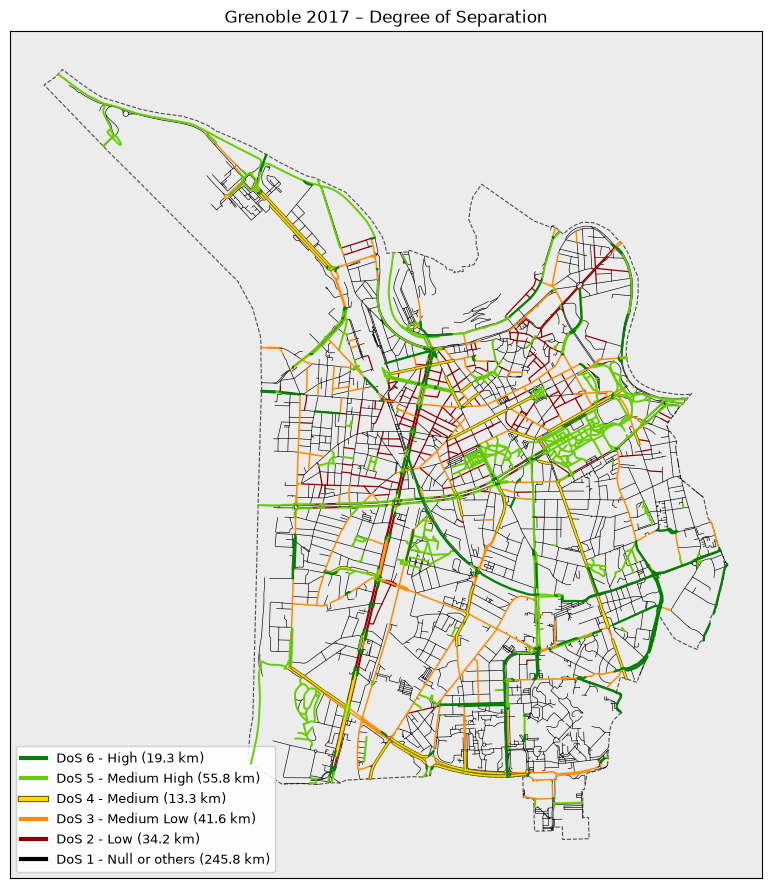

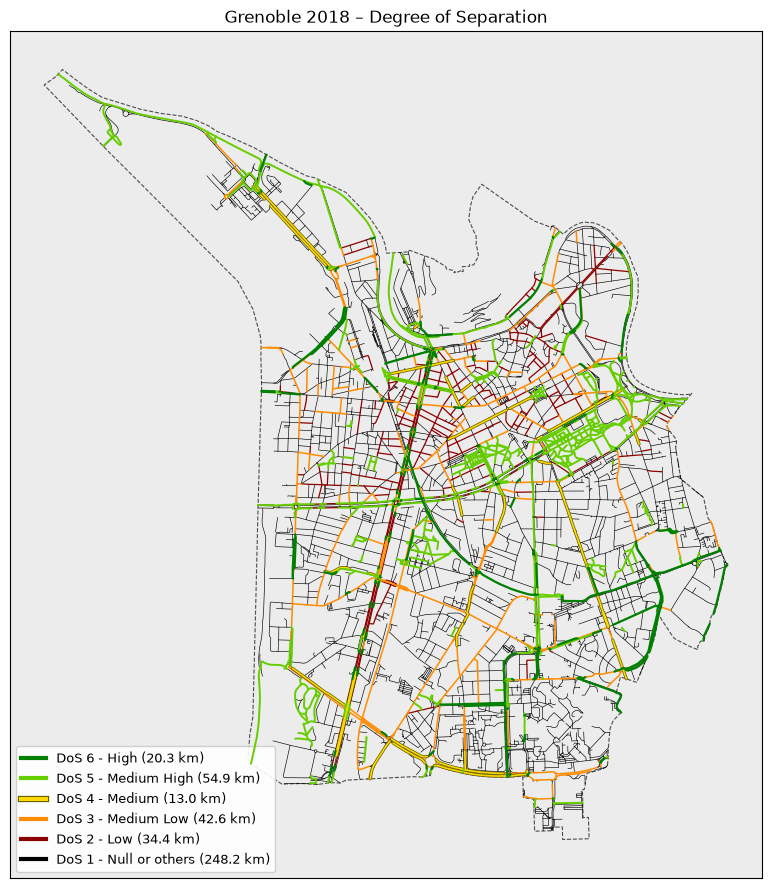

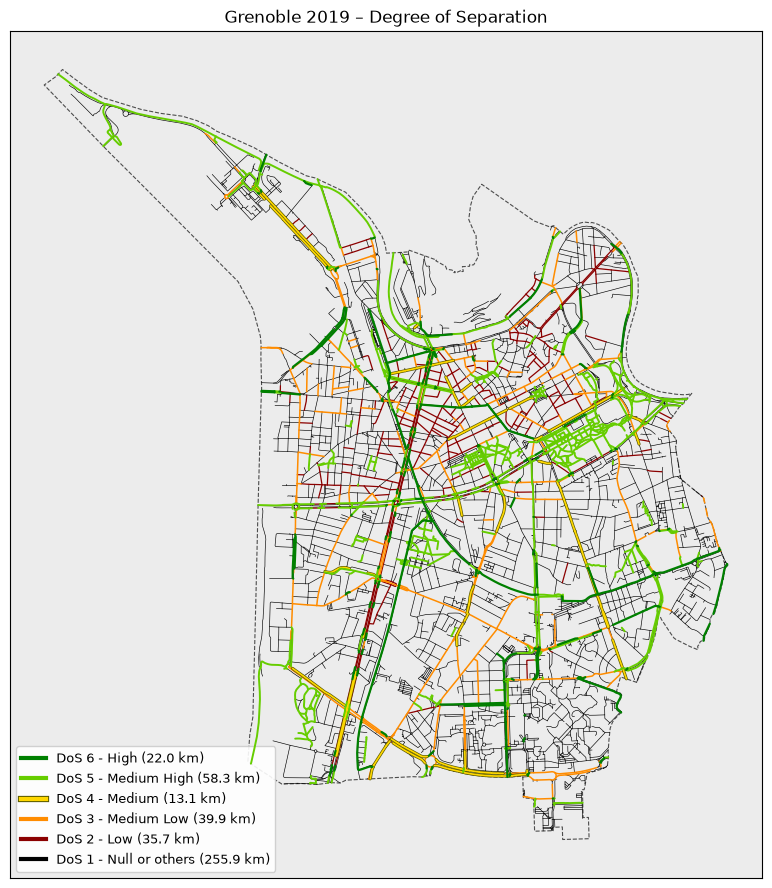

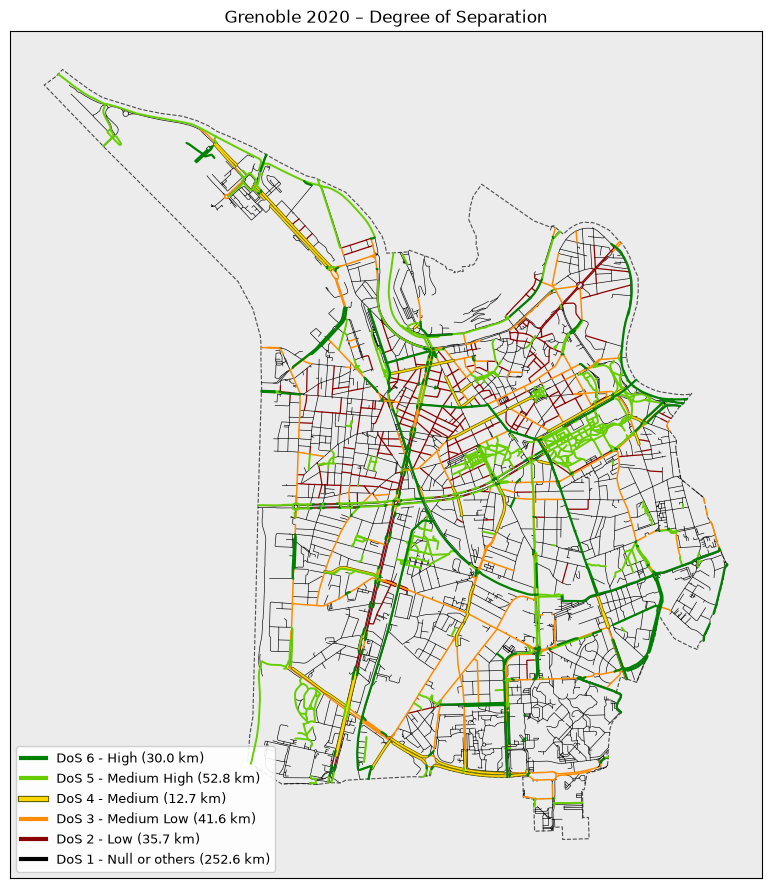

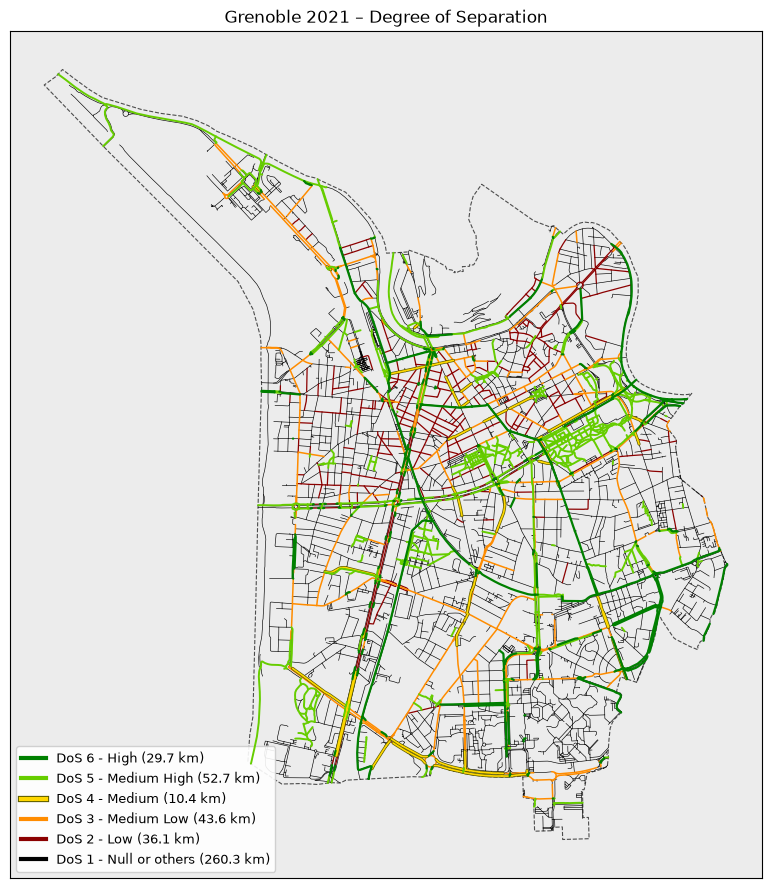

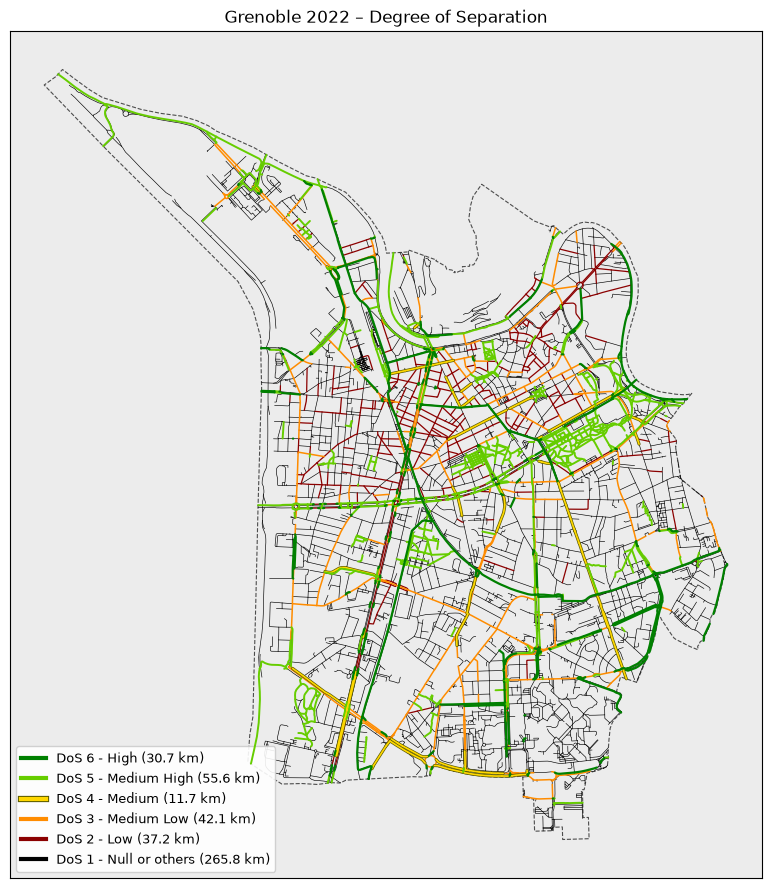

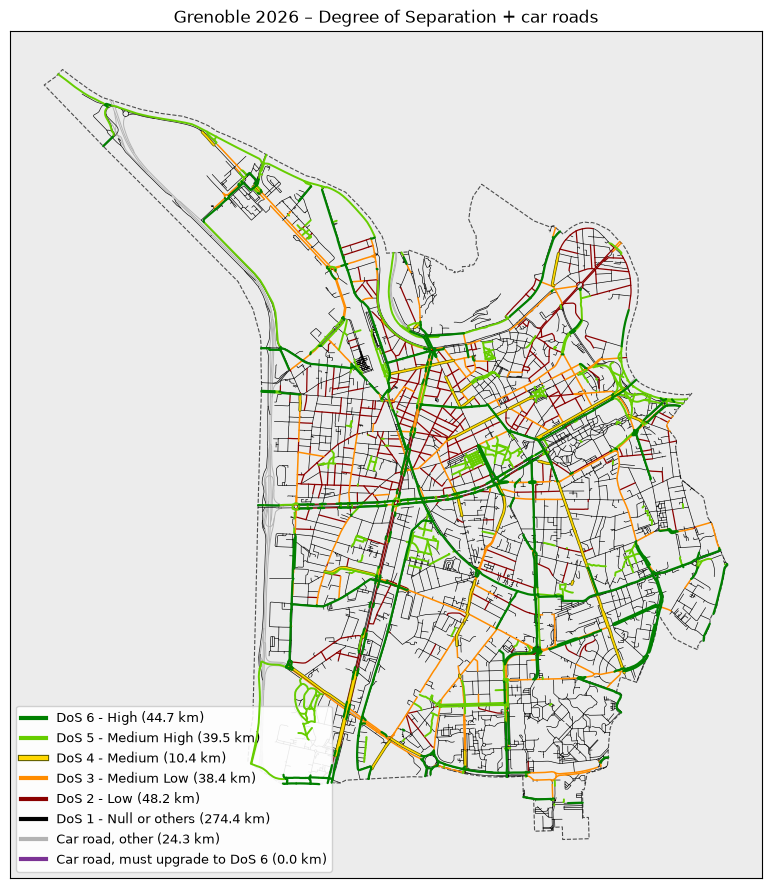

In [6]:
%matplotlib inline
for year, H in sorted(dos_graphs.items()):
    fig, ax = plt.subplots(figsize=(11, 11))
    title = f"{CITY} {year} – Degree of Separation" + (" + car roads" if year == CURRENT_YEAR else "")
    dos.plot_dos(H, title, boundary=poly, ax=ax, palette=DOS_PALETTE)
    fig.savefig(RUN / f"{SLUG}_dos_{year}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. All years side by side (bike network only)

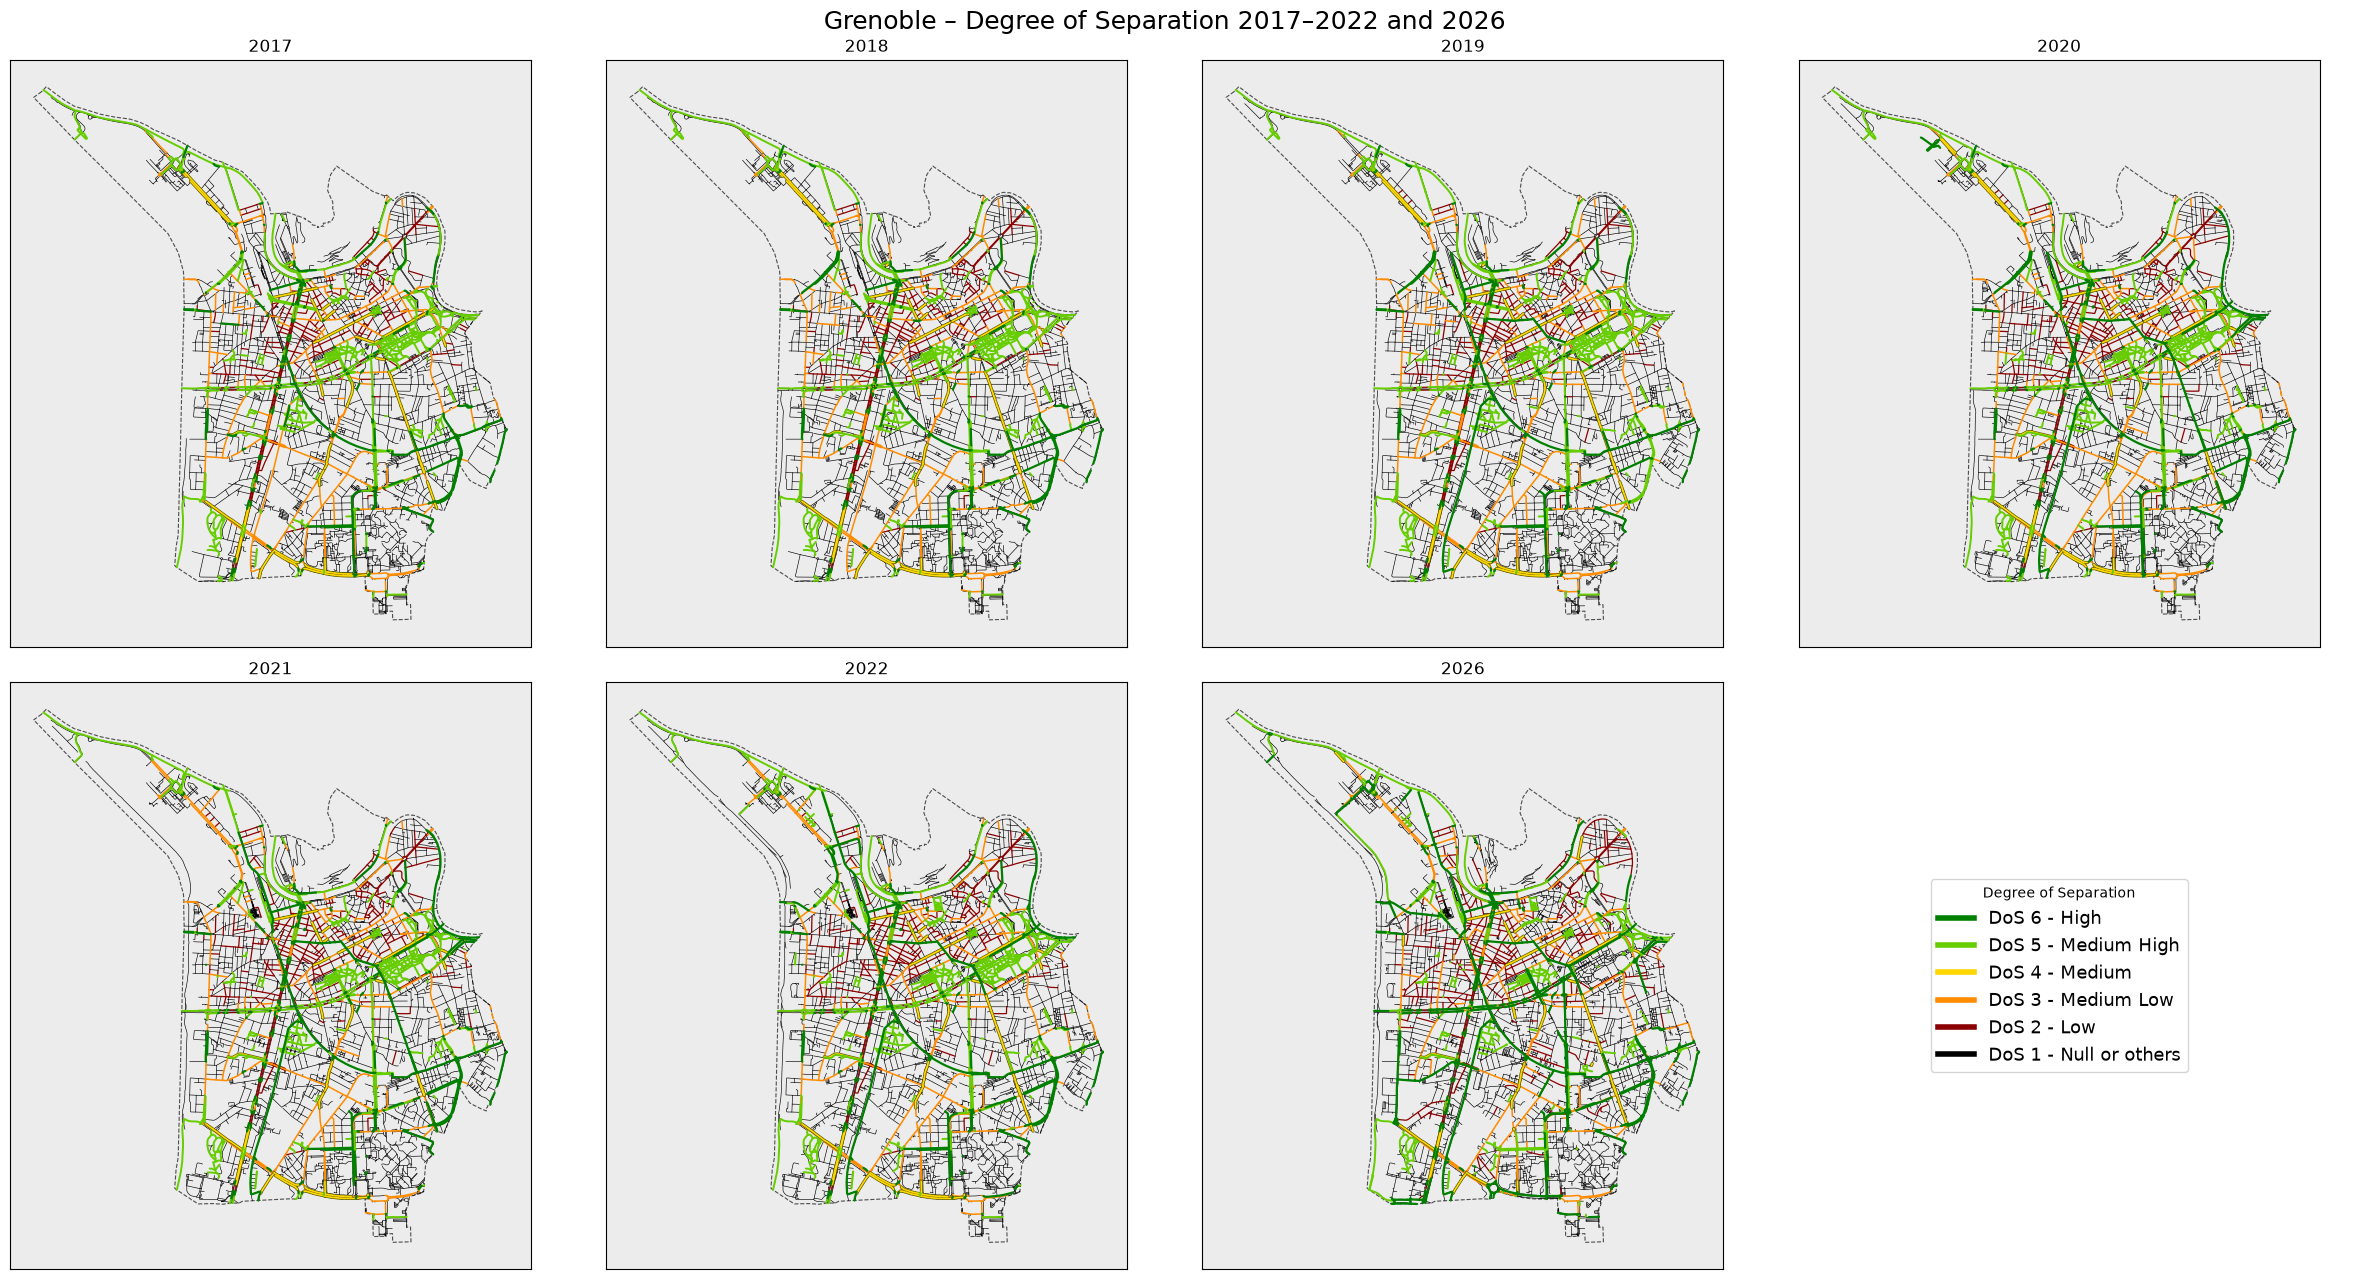

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(24, 13))
for ax, (year, H) in zip(axes.flat, sorted(dos_graphs.items())):
    dos.plot_dos(H, str(year), boundary=poly, ax=ax, show_cars=False, palette=DOS_PALETTE)
    ax.get_legend().remove()
axes.flat[-1].axis("off")
handles = [plt.Line2D([], [], color=DOS_PALETTE[l], lw=4, label=f"{dos.DOS_LABELS[l]}") for l in range(6, 0, -1)]
axes.flat[-1].legend(handles=handles, loc="center", fontsize=13, title="Degree of Separation")
fig.suptitle(f"{CITY} – Degree of Separation 2017–2022 and 2026", fontsize=18)
fig.tight_layout()
fig.savefig(RUN / f"{SLUG}_dos_all_years.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Interactive DoS map (zoom, pan, switch levels on/off)
Change `MAP_YEAR` to see another year. Also saved as HTML in the run folder.

In [8]:
MAP_YEAR = CURRENT_YEAR
m = dos.folium_dos(dos_graphs[MAP_YEAR], poly, title=f"{CITY} {MAP_YEAR} – Degree of Separation", palette=DOS_PALETTE)
m.save(str(RUN / f"{SLUG}_dos_{MAP_YEAR}_interactive.html"))
m

## 9. Where everything is saved

In [9]:
for p in sorted(RUN.rglob("*")):
    if p.is_file() and "osm_http_cache" not in p.parts:
        print(f"{p.stat().st_size/1e6:8.2f} MB  {p}")

    6.55 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2017\grenoble_bike_dos_2017_prepared.pkl
    2.08 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2017\grenoble_dos_2017_SIMPLE.pkl
    6.74 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2018\grenoble_bike_dos_2018_prepared.pkl
    2.13 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2018\grenoble_dos_2018_SIMPLE.pkl
    7.24 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2019\grenoble_bike_dos_2019_prepared.pkl
    2.23 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2019\grenoble_dos_2019_SIMPLE.pkl
    7.44 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2020\grenoble_bike_dos_2020_prepared.pkl
    2.27 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026-11-02\dos\2020\grenoble_dos_2020_SIMPLE.pkl
    7.97 MB  extras\dos_category\dos_output\grenoble\fresh_full_2026